# Lab 4.1 · A table on a folder: Iceberg

Day 4 · Session 1 · 25 min. What you'll do:
- watch a plain folder hand a reader a total that never existed;
- build an **Apache Iceberg** table and walk its files on disk;
- go back in time, add a column, and read the same table with three engines.

**Tasks**
- [ ] 1 · Catch a folder mid-rewrite (4')
- [ ] 2 · Create an Iceberg table and load two batches (6')
- [ ] 3 · Walk the metadata tree on disk (4')
- [ ] 4 · Change rows and time travel (6')
- [ ] 5 · Add a column; read with DuckDB and Polars (5')
- [ ] ✱ Stretch · Expire old snapshots and see which files stay on disk

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # solutions/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs\data\raw | quick mode: False


In [2]:
import json

import duckdb
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.compute as pc
from pyiceberg.types import StringType

import de_viz as V

pd.set_option("display.max_colwidth", 70)
WORK = U.lab_dir("D4_1", reset=True)
con = duckdb.connect()
con.sql("SET enable_progress_bar = false")
U.attach_app(con)


def orders_between(start, end):
    """Orders created in [start, end) from the app database, as an Arrow table."""
    return con.sql(f"""
        SELECT order_id, customer_id, store_id, status, payment_method, delivery_fee,
               created_at::TIMESTAMP AS created_at, updated_at::TIMESTAMP AS updated_at
        FROM app.orders WHERE created_at >= '{start}' AND created_at < '{end}' ORDER BY order_id
    """).to_arrow_table()

batch1 = orders_between("2026-08-01", "2026-08-04")
batch2 = orders_between("2026-08-04", "2026-08-08")
print(f"batch 1: {batch1.num_rows:,} orders | batch 2: {batch2.num_rows:,} orders")

batch 1: 1,868 orders | batch 2: 2,833 orders


## 1 · Catch a folder mid-rewrite (4')

Two Parquet files sit in a folder: that is the "table" most lakes start with. A job now has to fix the delivery fees
(add 15% VAT) and rewrites the files **one at a time**. Someone reads the folder between the two writes.

Run the cell. There is nothing to write.

In [3]:
FOLDER = WORK / "clean_orders"
FOLDER.mkdir()
PART_1, PART_2 = FOLDER / "part-1.parquet", FOLDER / "part-2.parquet"

def write_part(table, path, vat=False):
    fee = "round(delivery_fee * 1.15, 2)" if vat else "delivery_fee"
    con.register("_part", table)
    con.sql(f"COPY (SELECT * REPLACE ({fee} AS delivery_fee) FROM _part) TO '{path.as_posix()}' (FORMAT parquet)")

def total_fees():
    return con.sql(f"SELECT round(sum(delivery_fee), 2) FROM '{FOLDER.as_posix()}/*.parquet'").fetchall()[0][0]

write_part(batch1, PART_1)
write_part(batch2, PART_2)
before = total_fees()

write_part(batch1, PART_1, vat=True)      # the job has done one file...
during = total_fees()                     # ...and a reader arrives

write_part(batch2, PART_2, vat=True)      # the job finishes
after = total_fees()

print(f"before the job: {before:>12,.2f} SAR")
print(f"during the job: {during:>12,.2f} SAR   <- what the reader got")
print(f"after the job:  {after:>12,.2f} SAR")
U.check(before < during < after, "the reader got a total that was never true: part new, part old, and no error")

before the job:    40,635.00 SAR
during the job:    43,044.75 SAR   <- what the reader got
after the job:     46,730.25 SAR
✅ the reader got a total that was never true: part new, part old, and no error


🔍 Nothing failed and nothing warned. A bigger machine wouldn't help either. **What is missing is one place that says
which files are the table right now.** That is what a **table format** adds.

## 2 · Create an Iceberg table and load two batches (6')

**Apache Iceberg** is a table format: Parquet files plus metadata files that list exactly which Parquet files make up
the table. Three words you need:
- **Catalog**: maps a table name to its current metadata file. Here it's a small SQLite file. At work it's a service.
- **Snapshot**: one complete version of the table. Every write creates a new one.
- **Warehouse**: where the files go. A local folder here, cloud storage at work.

In [4]:
LAKE = WORK / "lakehouse"
catalog = U.get_catalog(LAKE)
catalog.create_namespace("qafila")
orders = catalog.create_table("qafila.orders", schema=batch1.schema)
print(orders.schema())
print("snapshots so far:", len(orders.snapshots()))

table {
  1: order_id: optional long
  2: customer_id: optional long
  3: store_id: optional string
  4: status: optional string
  5: payment_method: optional string
  6: delivery_fee: optional double
  7: created_at: optional timestamp
  8: updated_at: optional timestamp
}
snapshots so far: 0


✏️ **Exercise 1** · Append `batch1`, then `batch2`, to the table.

*Hint:* `table.append(arrow_table)`. Two lines.

In [5]:
def load_batches(table):
    table.append(batch1)
    table.append(batch2)

In [6]:
try:
    if orders.current_snapshot() is None:
        load_batches(orders)
except NotImplementedError:
    print("⏭️ Exercise 1 not done yet. Expected: 2 snapshots. Loading the reference so the lab can go on.")
    orders.append(batch1)
    orders.append(batch2)

n_loaded = orders.scan().to_arrow().num_rows
print(f"rows: {n_loaded:,} | snapshots: {len(orders.snapshots())}")
U.check(len(orders.snapshots()) == 2, "two appends made two snapshots")
U.check(n_loaded == batch1.num_rows + batch2.num_rows, "every order is in the table")
orders.inspect.snapshots().to_pandas()[["committed_at", "snapshot_id", "operation"]]

rows: 4,701 | snapshots: 2
✅ two appends made two snapshots
✅ every order is in the table


,committed_at,snapshot_id,operation
0,2026-10-30 20:43:21.672,3424373644069168613,append
1,2026-10-30 20:43:21.747,6647299775756616664,append


## 3 · Walk the metadata tree on disk (4')

Run both cells, then follow the tree from left to right: **metadata file → snapshot's manifest list → manifests → data
files**. A reader follows these pointers and never has to list a folder.

In [7]:
table_dir = LAKE / "qafila" / "orders"
for p in sorted(table_dir.rglob("*")):
    if p.is_file():
        name = str(p.relative_to(table_dir))
        print(f"{name[:18] + '…' + name[-22:] if len(name) > 41 else name:<42} {p.stat().st_size / 1e3:7.1f} kB")

meta = json.loads(Path(orders.metadata_location).read_text())
print("\ncurrent snapshot:", meta["current-snapshot-id"], "| snapshots listed:", len(meta["snapshots"]))

data\00000-0-0a27a…b-892d9f5da20b.parquet     38.7 kB
data\00000-0-2fdce…0-f835c903cb47.parquet     64.0 kB
metadata\00000-85a…d0a59742.metadata.json      1.1 kB
metadata\00001-8cb…6aebdb2c.metadata.json      2.0 kB
metadata\00002-c58…d41e0fa3.metadata.json      2.9 kB
metadata\0a27ad16-…b-892d9f5da20b-m0.avro      4.9 kB
metadata\2fdce685-…0-f835c903cb47-m0.avro      4.9 kB
metadata\snap-3424…800b-892d9f5da20b.avro      1.8 kB
metadata\snap-6647…b520-f835c903cb47.avro      1.9 kB

current snapshot: 6647299775756616664 | snapshots listed: 2


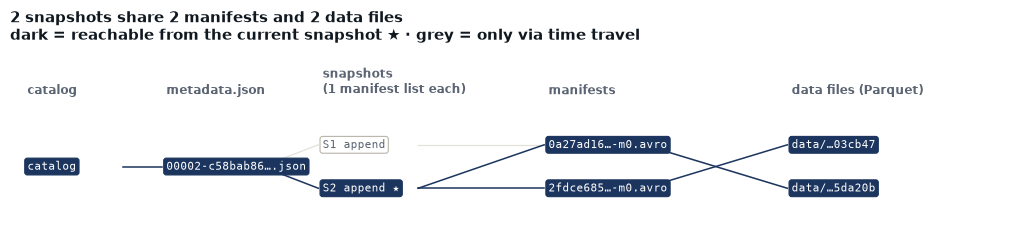

In [8]:
V.iceberg_tree(orders.metadata_location)

🔍 Look at the file list: how many `*.metadata.json` files are there, and how many Parquet files? The **commit** is the
single step that points the catalog at a new metadata file. Before that step, readers see the old version whole. After
it, they see the new one whole. That is the **atomic commit** the folder didn't have.

## 4 · Change rows and time travel (6')

Parquet files are never edited. An update writes new files and a new snapshot, and the old snapshot stays readable. Two
real changes for Qafila: five orders were refunded, and one customer asked for their orders to be deleted. Run the cell.

In [9]:
refund_ids = batch1["order_id"].to_pylist()[:5]
refunds = batch1.filter(pc.is_in(batch1["order_id"], pa.array(refund_ids)))
refunds = refunds.set_column(refunds.schema.get_field_index("status"), "status", pa.array(["refunded"] * 5))
print(orders.upsert(refunds, join_cols=["order_id"]))

erased_customer = batch1["customer_id"][7].as_py()
orders.delete(delete_filter=f"customer_id = {erased_customer}")
print("deleted the orders of customer", erased_customer)
print("snapshots now:", len(orders.snapshots()))

UpsertResult(rows_updated=5, rows_inserted=0)


deleted the orders of customer 105495
snapshots now: 5


✏️ **Exercise 2** · Write `rows_at(snapshot_id)`: how many rows the table had **as of that snapshot**.

*Hint:* `orders.scan(snapshot_id=snapshot_id)` reads an old version. `.to_arrow().num_rows` counts it. One line.

In [10]:
def rows_at(snapshot_id):
    return orders.scan(snapshot_id=snapshot_id).to_arrow().num_rows

In [11]:
try:
    rows_at(orders.snapshots()[0].snapshot_id)
except NotImplementedError:
    print("⏭️ Exercise 2 not done yet. Expected: one count per snapshot, shrinking at the delete. Using the reference.")
    def rows_at(snapshot_id):
        return orders.scan(snapshot_id=snapshot_id).to_arrow().num_rows

def refunded_at(snapshot_id):
    return orders.scan(snapshot_id=snapshot_id, row_filter="status == 'refunded'").to_arrow().num_rows

history = pd.DataFrame([{"snapshot": f"S{i}", "operation": s.summary.operation.value, "rows": rows_at(s.snapshot_id),
                         "refunded": refunded_at(s.snapshot_id)} for i, s in enumerate(orders.snapshots(), 1)])
U.check(history.rows.iloc[1] == batch1.num_rows + batch2.num_rows, "time travel still sees the version before the changes")
U.check(history.rows.iloc[-1] < history.rows.iloc[1], "the current version has fewer rows after the delete")
U.check(history.refunded.iloc[-1] == history.refunded.iloc[1] + 5, "the five new refunds are in the current version")
history

✅ time travel still sees the version before the changes
✅ the current version has fewer rows after the delete
✅ the five new refunds are in the current version


,snapshot,operation,rows,refunded
0,S1,append,1868,28
1,S2,append,4701,85
2,S3,overwrite,4696,85
3,S4,append,4701,90
4,S5,overwrite,4700,90


🔍 The upsert took two snapshots: one removes the old versions of the five orders, one appends the new versions. Which
snapshot would you read to find out what a dashboard showed yesterday? And notice: **the deleted customer's orders are
still readable in the older snapshots.** A real erasure also has to expire those snapshots and remove their files.

## 5 · Add a column; read with DuckDB and Polars (5')

The app starts recording the sales `channel`. With a folder of Parquet files you'd have to decide what to do with every
old file. With Iceberg, the column is added to the metadata only.

✏️ **Exercise 3** · Add an optional text column `channel` to the table.

*Hint:*
```python
with table.update_schema() as update:
    update.add_column("channel", StringType())
```

In [12]:
def add_channel(table):
    with table.update_schema() as update:
        update.add_column("channel", StringType())

In [13]:
parquet_before = U.count_files(table_dir / "data")
try:
    if "channel" not in orders.schema().column_names:
        add_channel(orders)
except NotImplementedError:
    print("⏭️ Exercise 3 not done yet. Expected: a `channel` column and no new data file. Using the reference.")
    with orders.update_schema() as update:
        update.add_column("channel", StringType())

U.check("channel" in orders.schema().column_names, "the column is in the table")
U.check(U.count_files(table_dir / "data") == parquet_before, "not one data file was rewritten")

# new rows carry a channel; old rows read it as NULL
sept = orders_between("2026-09-01", "2026-09-02")
orders.append(sept.append_column("channel", pa.array(["app"] * sept.num_rows, pa.string())))
print("rows with a channel:", orders.scan(row_filter="channel == 'app'").to_arrow().num_rows,
      "| rows without:", orders.scan(row_filter="channel is null").to_arrow().num_rows)

✅ the column is in the table
✅ not one data file was rewritten


rows with a channel: 701 | rows without: 4700


The point of an **open** format: any engine that speaks Iceberg can read the same files. Run this to ask DuckDB and
Polars the same question.

In [14]:
U.duckdb_iceberg(con)
meta_path = orders.metadata_location
by_store_duck = con.sql(f"""
    SELECT store_id, count(*) AS orders FROM iceberg_scan('{meta_path}')
    WHERE created_at < '2026-09-01' GROUP BY store_id ORDER BY store_id
""").pl()
by_store_pl = (pl.scan_iceberg(orders)
                 .filter(pl.col("created_at") < pl.datetime(2026, 9, 1))
                 .group_by("store_id").agg(pl.len().alias("orders"))
                 .sort("store_id").collect())
U.check(by_store_duck["orders"].to_list() == by_store_pl["orders"].to_list(), "DuckDB and Polars read the same table state")
print("August orders, both engines:", by_store_duck["orders"].sum())
by_store_duck.head()

✅ DuckDB and Polars read the same table state
August orders, both engines: 4700


store_id,orders
str,i64
"""DMM-01""",445
"""DMM-02""",354
"""JED-01""",472
"""JED-02""",381
"""JED-03""",298


🔍 One copy of the data, one answer to "what's in the table right now". Which engine you pick becomes a choice per job.

## ✱ Stretch · Expire old snapshots and see which files stay on disk

Expire every snapshot except the current one, then compare the files on disk.

In [15]:
def stretch():
    before_files = set(table_dir.rglob("*.parquet"))
    current = orders.current_snapshot().snapshot_id
    orders.maintenance.expire_snapshots().by_ids([s.snapshot_id for s in orders.snapshots() if s.snapshot_id != current]).commit()
    orders.refresh()
    after_files = set(table_dir.rglob("*.parquet"))
    print("snapshots left:", len(orders.snapshots()))
    print(f"parquet files on disk: {len(before_files)} -> {len(after_files)}")

try:
    stretch()
except NotImplementedError:
    print("✱ Optional: write `stretch()` if you have time.")

snapshots left: 1
parquet files on disk: 6 -> 6


🔍 Time travel to the old versions is gone, but PyIceberg leaves the files on disk. A separate cleanup job removes them.

## Checkpoint

1. Why can't a folder of Parquet files give a reader one consistent version during a rewrite?

<details><summary>Answer</summary>Files change one at a time and nothing says which set is current, so a reader in the middle gets a mix. Iceberg's list of files changes in one step.</details>

2. What does the catalog store, and why must every engine agree on it?

<details><summary>Answer</summary>The location of the table's current metadata file. It decides which snapshot is "now": engines that use the same catalog see the same version.</details>

3. You deleted a customer's orders. Are they gone?

<details><summary>Answer</summary>Not yet. They are gone from the current snapshot, but old snapshots and their files still hold them until you expire the snapshots and remove the files.</details>

## Carry forward

Next you'll meet Spark, one more engine that can read tables like this. In the capstone, Iceberg is an option for your
gold tables, not a requirement. Want more? `tools/iceberg.ipynb`.